# Decoder Layer

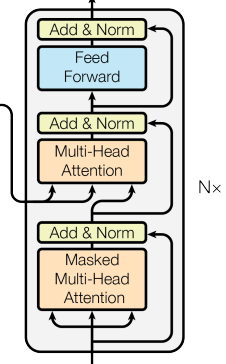

In [1]:
from pathlib import Path
import sys

path = Path().resolve().parents[1]

if str(path) not in sys.path:
    sys.path.append(str(path))

In [2]:
import torch
import torch.nn as nn
from src.model import MultiHeadAttention, PositionWiseFFN

In [ ]:
class DecoderLayer(nn.Module):
    def __init__(
            self,
            d_model: int,
            d_ff: int,
            num_heads: int,
            device: torch.device,
            dropout: float # padrão do paper 2048
        ):

        super().__init__()

        self.masked_mha = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            device=device,
            dropout=dropout
        )

        self.mha = MultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            device=device,
            dropout=dropout
        )

        self.ffn = PositionWiseFFN(
            d_model=d_model,
            d_ff=d_ff,
            device=device,
            dropout=dropout
        )

        #layer norms
        self.norm_masked_mha = nn.LayerNorm(
            d_model,
            device=device
        )

        self.norm_mha = nn.LayerNorm(
            d_model,
            device=device
        )
                
        self.norm_ffn = nn.LayerNorm(
            d_model,
            device=device    
        )


    def forward(
        self,
        x: torch.Tensor,
        memory: torch.Tensor,
        is_causal: bool = True,
        src_mask: torch.Tensor | None = None, # padding mask
        tgt_padding: torch.Tensor | None = None

    ):
        

        #masked attention
        masked_mha_output = self.masked_mha(
            x, x, x,
            is_causal=is_causal,
            attn_mask=tgt_padding
        )
        x = self.norm_masked_mha(x + masked_mha_output)

        #cross attention
        '''
            x: [Batch, Target Lenght, d_model]      -> entrada do decoder
            memory: [Batch, Source Lenght, d_model] -> output do encoder
        '''
        mha_output = self.mha(
            x, memory, memory,
            attn_mask=src_mask
        ) #Q vem do decoder -> faz a requisição / K e V vem do encoder
        x = self.norm_mha(x + mha_output)

        #feed forward
        ffn_output = self.ffn(x)
        x = self.norm_ffn(x + ffn_output)
        return x

# Decoder

In [ ]:
class Decoder(nn.Module):
    def __init__(
        self, 
        d_model:int,
        d_ff:int,
        num_heads:int,
        num_layers: int = 6,
        device: torch.device | None = None,
        dropout: float = 0.1
    ):
        
        super().__init__()

        self.layers = nn.ModuleList([
            DecoderLayer(
                d_model=d_model,
                d_ff=d_ff,
                num_heads=num_heads,
                device=device,
                dropout=dropout
            ) for _ in range(num_layers)
        ])

    def forward(
        self,
        x: torch.Tensor,
        memory: torch.Tensor,
        is_causal: bool = True,
        src_mask: torch.Tensor | None = None,
        tgt_padding: torch.Tensor | None = None
    ):

        for layer in self.layers:
            x = layer(
                x, memory,
                src_mask=src_mask,
                is_causal=is_causal,
                tgt_padding=tgt_padding
            )

        return x

- Input do Encoder: sequencia de origem que entra no encoder
- Input do Decoder: sequência alvo que entra no decoder

---

- CROSS-ATTENTION:
    - Encoder: pergunta (envia query)
    - Decoder: responder (keys and values)